# PPO：Real-only、PR30、PR10 的 Sharpe 選模比較

目的：在相同 PPO 設定、seeds 0–9 與訓練預算下，判斷兩種合成資料是否改善 validation 的報酬與風險。

**主要規則：每組、每個 seed，選擇 2018–2019 validation Sharpe 最高的 checkpoint；同分取較早者。**
次要分析保留固定最後 500k checkpoint，呈現選模與訓練長度的影響。

本 notebook 只讀取已完成的 CSV、JSON 與圖表，不啟動 PPO、不執行 test。選模與主要評分使用同一 validation，因此分數具有選擇偏差。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [p / "FinRL_Exp" for p in candidates.copy()]
ROOT = next(p for p in candidates if (p / "finrl/experiments/scenario_mix.py").exists())
OUT = ROOT / "results/scenario_mix/joint_pr30_pr10_real_only_sharpe_20261018"
A = json.loads((OUT / "analysis.json").read_text())
assert A["status"] == "complete" and A["test_evaluation_performed"] is False
GROUPS = ["REAL_ONLY", "PR30_B50", "PR10_B50"]
LABELS = {"REAL_ONLY": "Real-only", "PR30_B50": "PR30", "PR10_B50": "PR10", "BUY_HOLD": "買入持有"}
selected = pd.read_csv(OUT / "selected_checkpoints.csv")
summary = pd.read_csv(OUT / "selected_summary.csv").set_index("group").loc[GROUPS]
pairs = pd.read_csv(OUT / "paired_seed_differences.csv")
assert len(selected) == 30 and not selected.duplicated(["group", "seed"]).any()
assert selected.groupby("group").seed.apply(lambda x: set(x) == set(range(10))).all()
pd.set_option("display.max_columns", 12)
display(pd.DataFrame({"設定": ["PPO 訓練期間", "Validation", "每組 seeds", "Workers", "訓練步數", "驗證頻率", "合成 episode 機率", "Checkpoint 規則"],
                      "值": ["2010–2017", "2018–2019，503 個日報酬", "0–9，共 10 個", "5", "名義 500,000；實際 532,480", "每 25,000 名義步數", "Real-only = 0；PR30 / PR10 = 0.5", "Validation Sharpe 最大；同分取較早者"]}))


,設定,值
0,PPO 訓練期間,2010–2017
1,Validation,2018–2019，503 個日報酬
2,每組 seeds,0–9，共 10 個
3,Workers,5
4,訓練步數,"名義 500,000；實際 532,480"
5,驗證頻率,"每 25,000 名義步數"
6,合成 episode 機率,Real-only = 0；PR30 / PR10 = 0.5
7,Checkpoint 規則,Validation Sharpe 最大；同分取較早者


## 選模後的整體比較

表格為 **10 seeds 的平均 ± 標準差**；買入持有使用相同十檔股票與現金各 1/11 的初始配置，計入建倉成本。
報酬是兩年累積淨報酬，並非年化報酬。最大回撤與 ES95 以正的損失幅度表示，越低越好。


,累積報酬 (%),Sharpe,Calmar,最大回撤 (%),日 ES95 (%)
Real-only,42.77 ± 3.35,1.131 ± 0.032,1.203 ± 0.061,16.38 ± 1.37,2.46 ± 0.12
PR30,45.83 ± 9.02,1.195 ± 0.069,1.326 ± 0.221,15.79 ± 1.28,2.43 ± 0.23
PR10,43.24 ± 3.03,1.153 ± 0.055,1.259 ± 0.116,15.81 ± 0.68,2.44 ± 0.05
買入持有,41.29,1.079,1.132,16.82,2.51


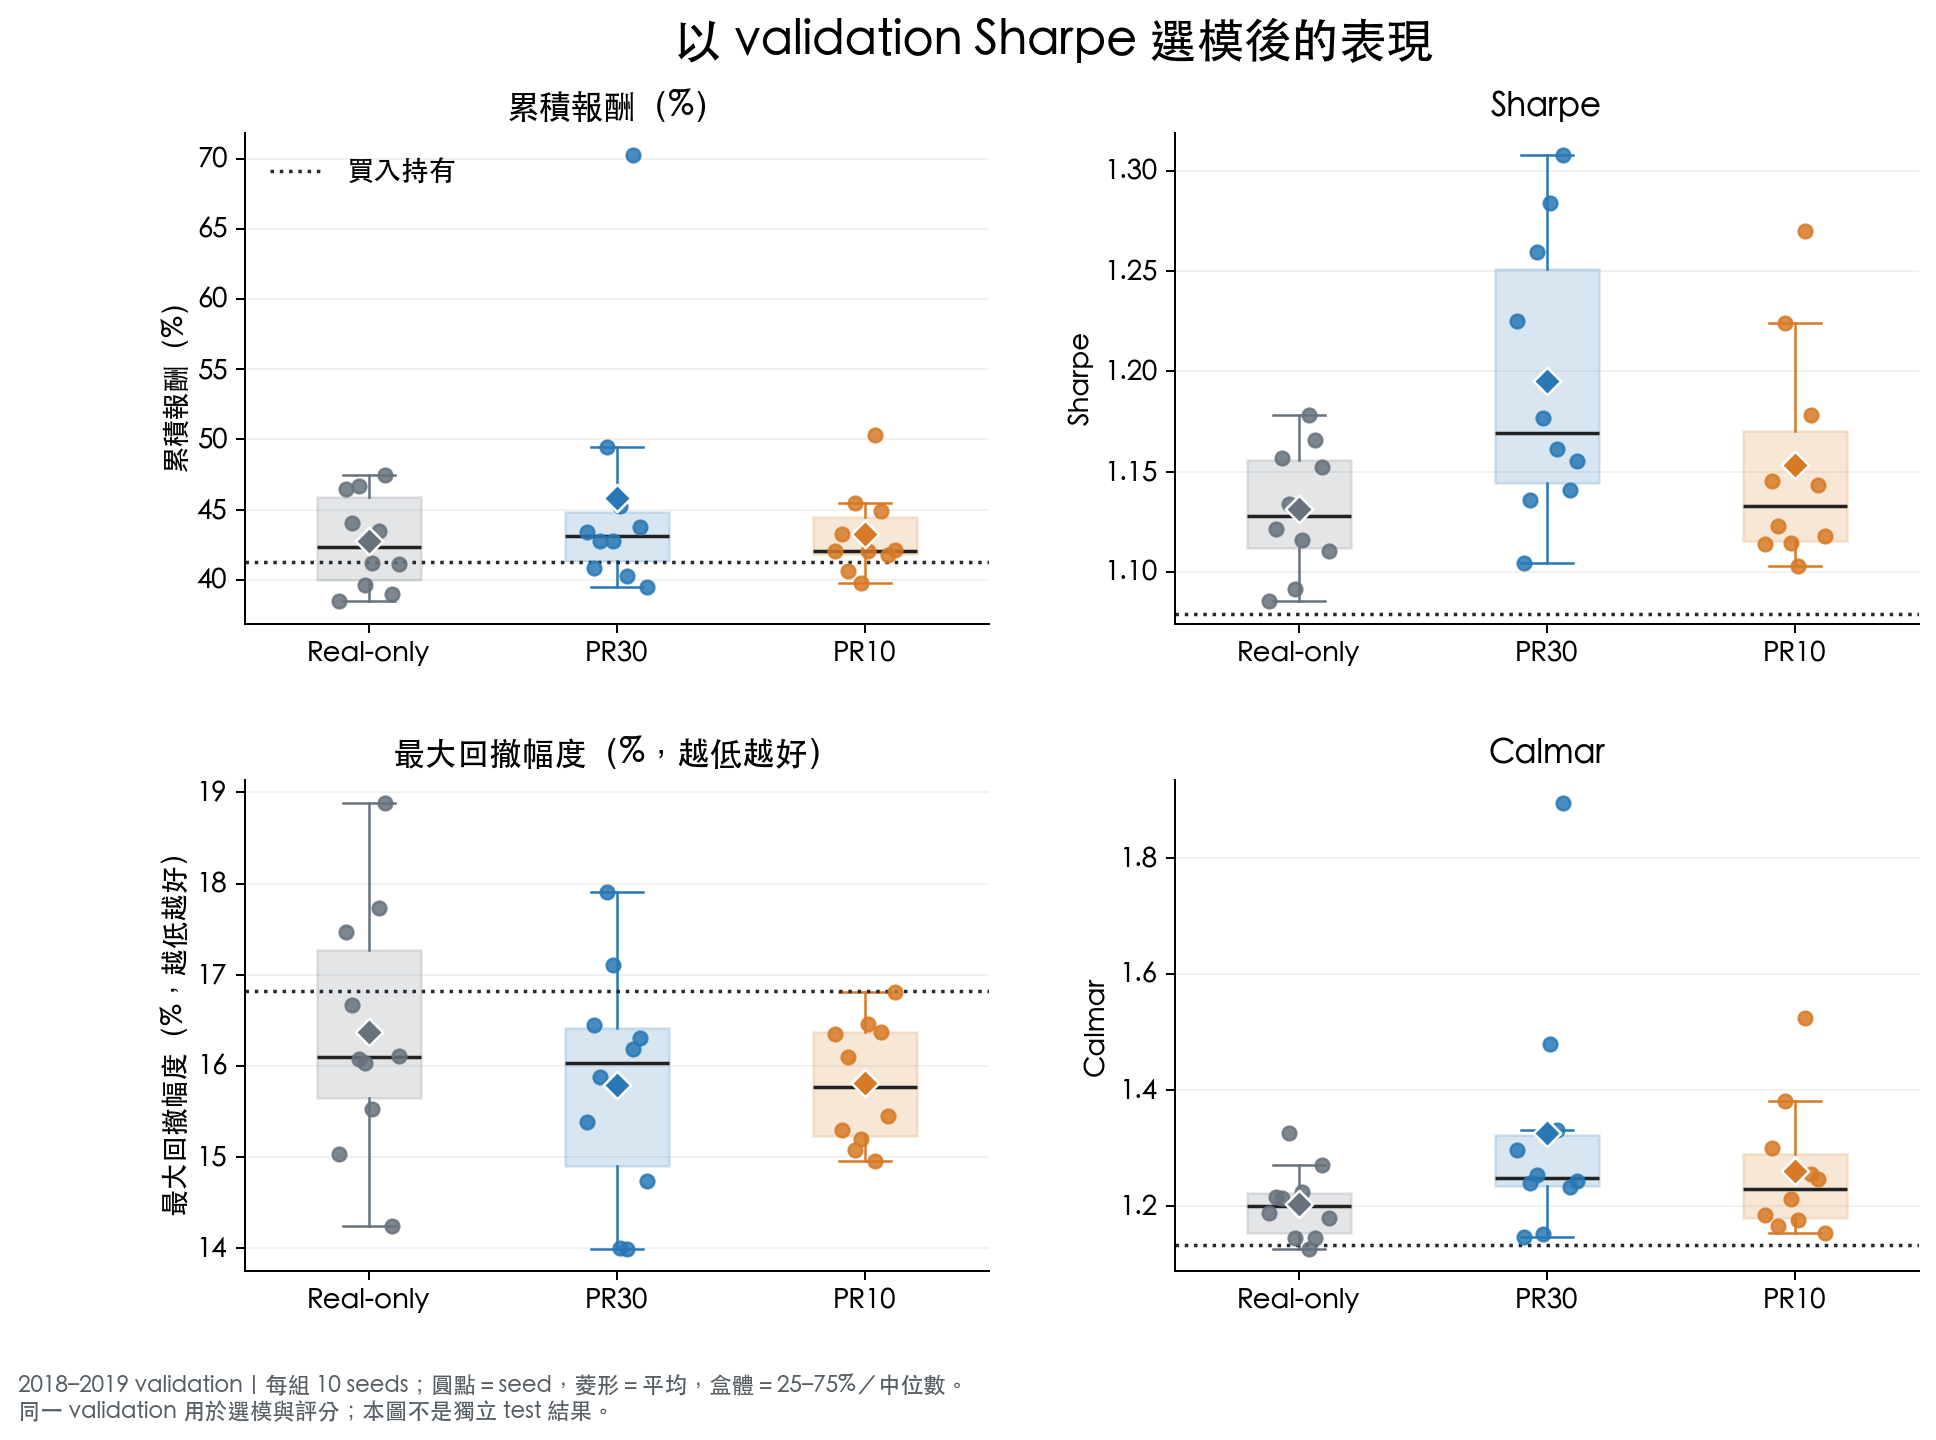

In [2]:
metric_labels = {"return_pct": "累積報酬 (%)", "sharpe": "Sharpe", "calmar": "Calmar", "mdd_pct": "最大回撤 (%)", "es95_daily_pct": "日 ES95 (%)"}
table = pd.DataFrame(index=[LABELS[g] for g in GROUPS] + ["買入持有"])
for key, label in metric_labels.items():
    digits = 3 if key in ["sharpe", "calmar"] else 2
    table[label] = [f"{summary.loc[g, key+'_mean']:.{digits}f} ± {summary.loc[g, key+'_sd']:.{digits}f}" for g in GROUPS] + [f"{A['buy_hold'][key]:.{digits}f}"]
display(table)
display(Image(filename=str(OUT / "figures/01_selected_metrics.png"), width=1100))


### 主要觀察

- **PR30 在這段 validation 的 Sharpe 有正向訊號**：相對 real-only 的平均差為 +0.064，配對 bootstrap 95% 區間為 [+0.019, +0.109]。
- **PR10 的增幅較小**：Sharpe 平均差 +0.022，區間 [-0.000, +0.047] 仍跨零。
- 兩種合成組的平均最大回撤為 15.79%／15.81%，非常接近。相對 real-only 的回撤與 ES95 改善區間仍跨零，不能據此確證尾部風險改善。
- PR30 的平均報酬受到高報酬 seed 影響，需同時查看分布、中位數與單股集中度。
- seed 8 的後段單股集中也出現在 real-only，應優先檢查共同的 PPO 訓練行為；本批資料不足以直接判定優化器或網路設計中的哪個機制造成集中。

以上結論限於同一 validation 的選模比較；尚未執行獨立 test。


## 配對差異與不確定性

以 seed 作為比較單位，進行 200,000 次配對 bootstrap。區間是平均差的 95% percentile 區間；只反映這十個訓練 seeds 的變異。
Real-only 與混合組共用 seed 編號與超參數，但 p 改變後的 episode 隨機序列不同。不能把 600 個 checkpoints 或 503 個市場日視為獨立訓練重複。


,比較,指標,平均差,95% 區間,實驗組較佳 seeds
0,PR30 − Real-only,累積報酬 (%),+3.059,"[-0.881, +8.168]",6/10
1,PR30 − Real-only,Sharpe,+0.064,"[+0.019, +0.109]",6/10
2,PR30 − Real-only,最大回撤 (%),-0.582,"[-1.703, +0.526]",6/10
3,PR30 − Real-only,日 ES95 (%),-0.032,"[-0.142, +0.100]",7/10
4,PR10 − Real-only,累積報酬 (%),+0.469,"[-1.366, +2.459]",6/10
5,PR10 − Real-only,Sharpe,+0.022,"[-0.000, +0.047]",7/10
6,PR10 − Real-only,最大回撤 (%),-0.569,"[-1.495, +0.335]",6/10
7,PR10 − Real-only,日 ES95 (%),-0.024,"[-0.099, +0.049]",5/10
8,PR10 − PR30,累積報酬 (%),-2.590,"[-8.514, +1.998]",3/10
9,PR10 − PR30,Sharpe,-0.042,"[-0.091, +0.008]",3/10


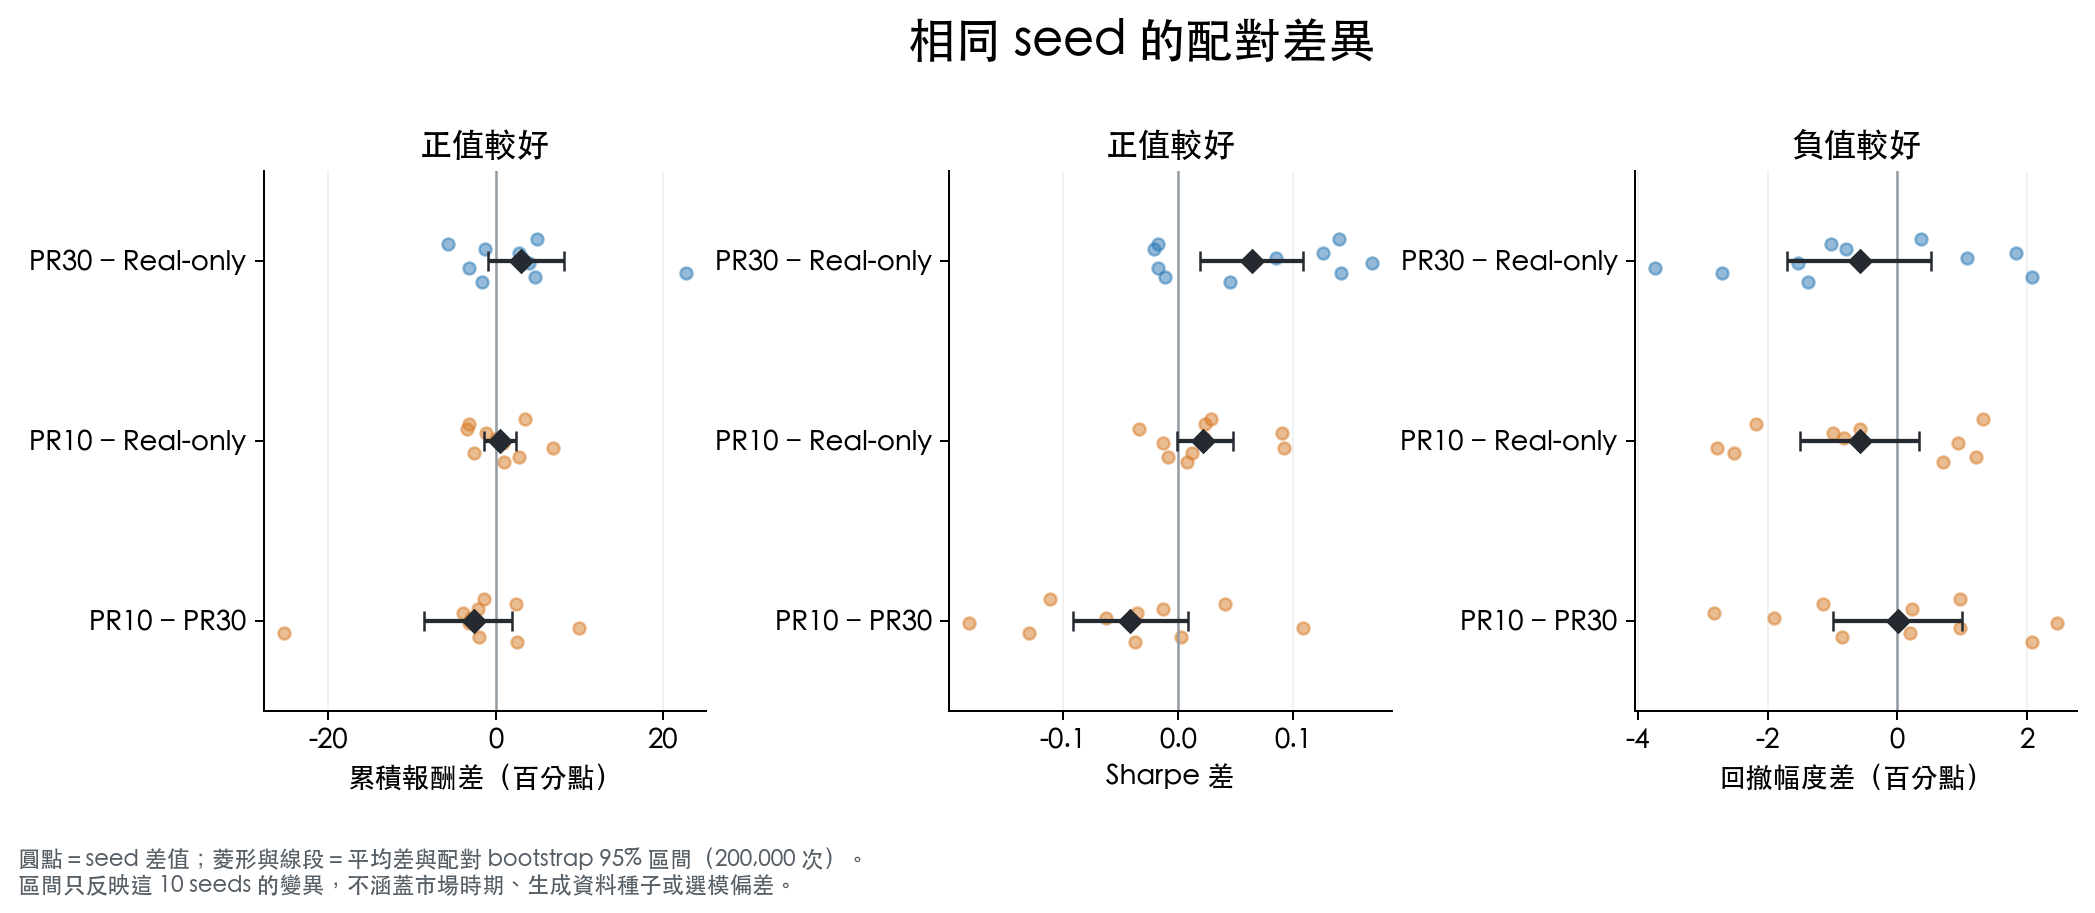

In [3]:
p = pairs[pairs.metric.isin(["return_pct", "sharpe", "mdd_pct", "es95_daily_pct"])].copy()
p["比較"] = p.treatment.map(LABELS) + " − " + p.control.map(LABELS)
p["指標"] = p.metric.map(metric_labels)
p["平均差"] = p.mean_difference.map(lambda x: f"{x:+.3f}")
p["95% 區間"] = p.apply(lambda r: f"[{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]", axis=1)
p["實驗組較佳 seeds"] = p.treatment_better_seeds.map(lambda x: f"{x}/10")
display(p[["比較", "指標", "平均差", "95% 區間", "實驗組較佳 seeds"]].reset_index(drop=True))
display(Image(filename=str(OUT / "figures/04_paired_differences.png"), width=1100))


## 訓練長度與 checkpoint

曲線為每個訓練 checkpoint 在同一 validation 的分數；色帶是 seeds 的 25–75% 範圍，不是信賴區間。
選模表保留各 seed 的實際 checkpoint，不混用不同選模指標。


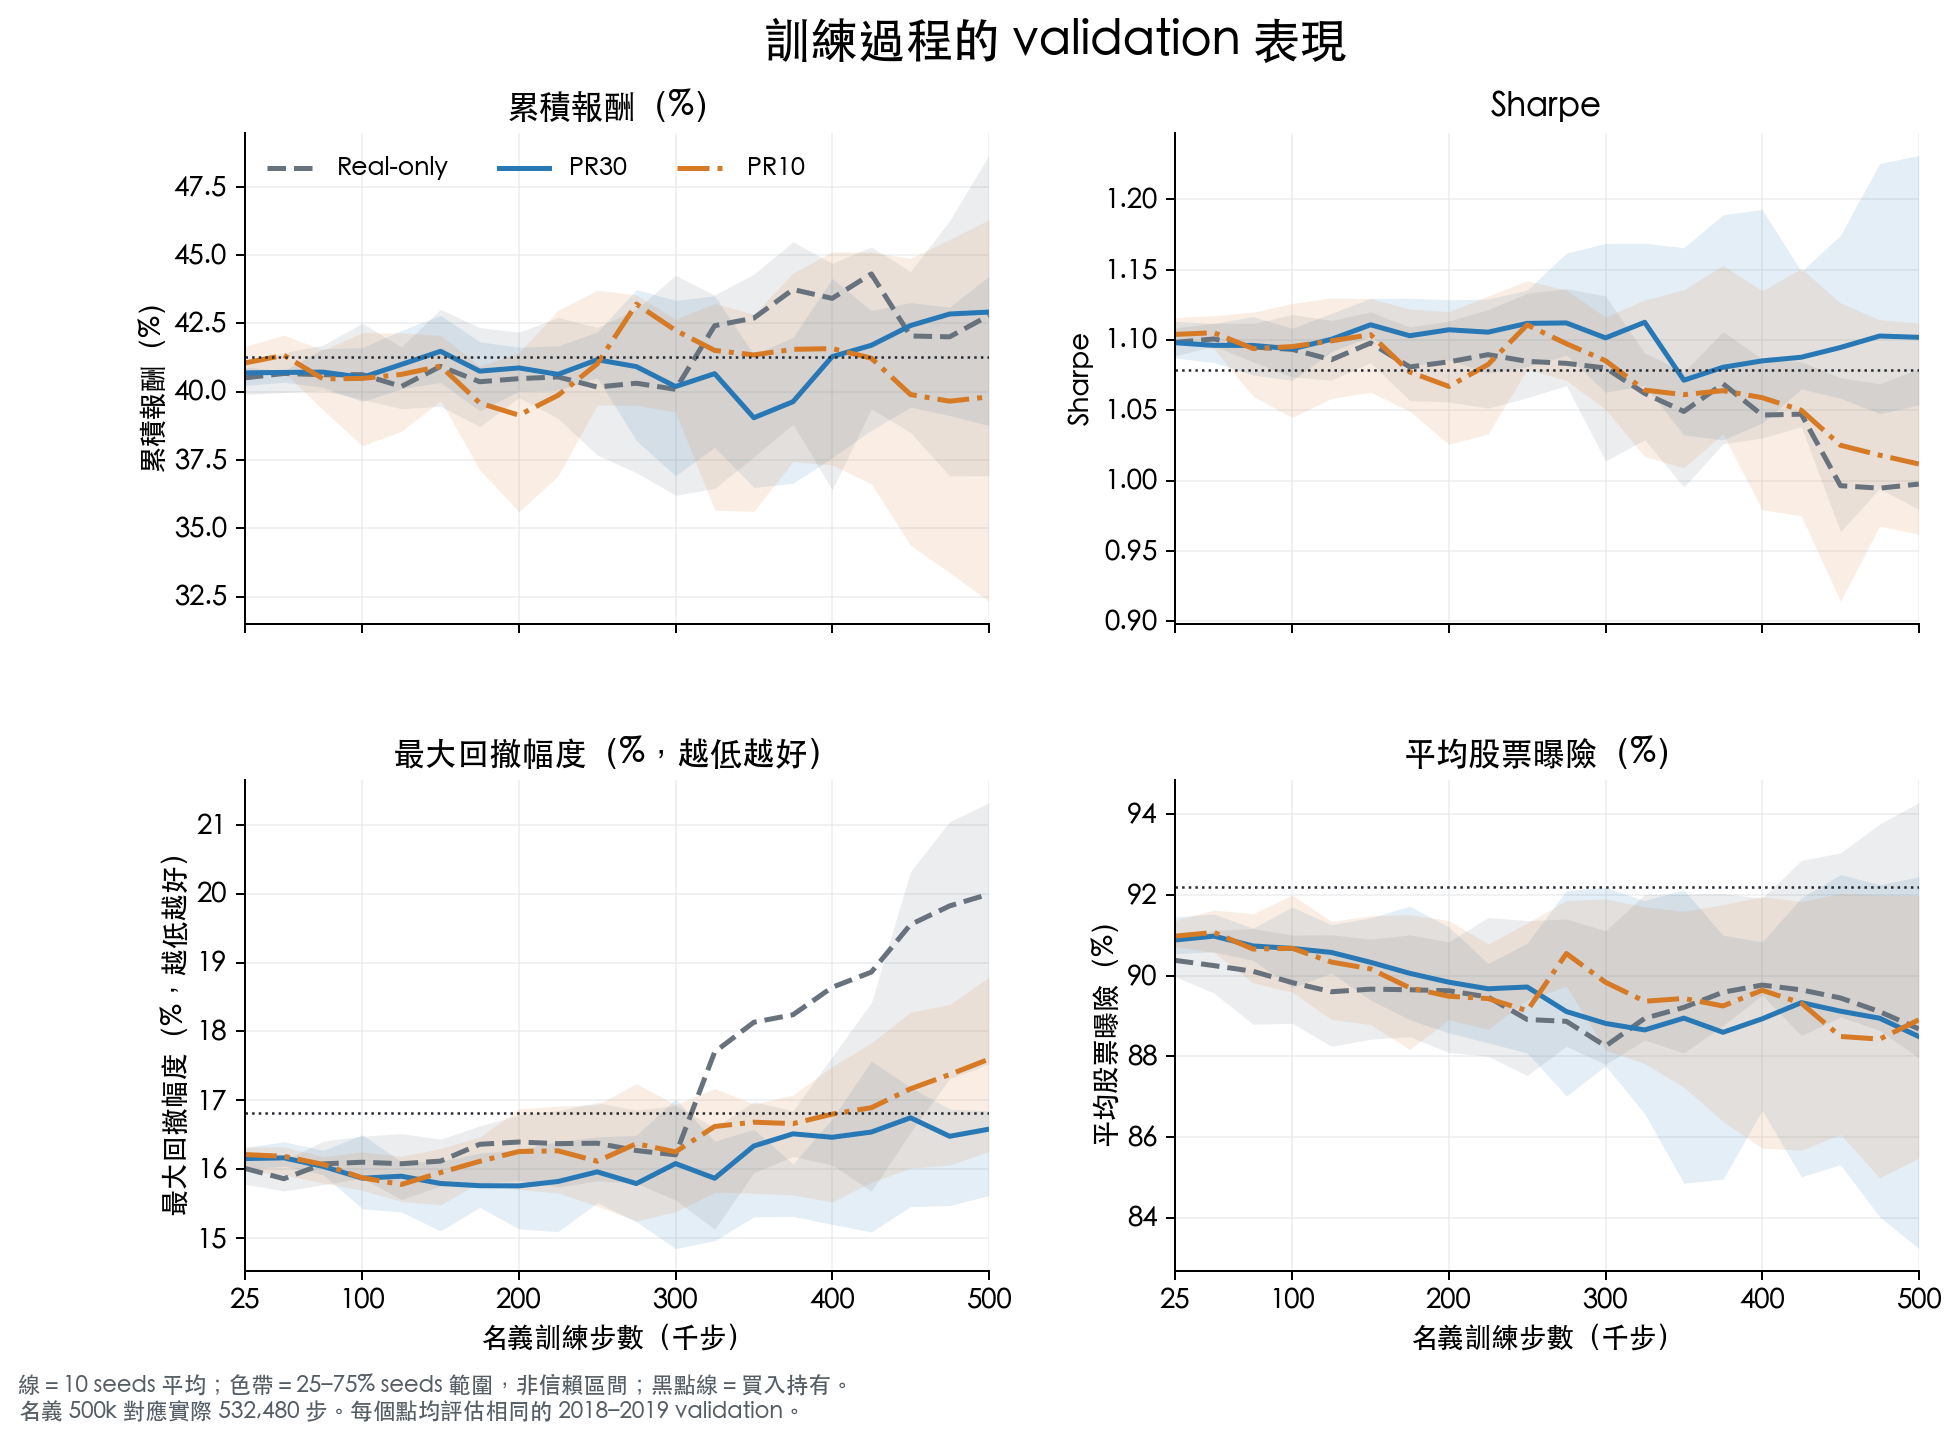

group,Real-only,PR30,PR10
seed,,,
0,"50,000","450,000","25,000"
1,"425,000","25,000","275,000"
2,"375,000","450,000","25,000"
3,"375,000","500,000","150,000"
4,"25,000","475,000","250,000"
5,"225,000","500,000","100,000"
6,"225,000","350,000","425,000"
7,"300,000","500,000","125,000"
8,"300,000","250,000","250,000"


,sharpe_selected,sharpe_final,return_pct_selected,return_pct_final,mdd_pct_selected,mdd_pct_final
group,,,,,,
PR10,1.153,1.012,43.235,39.815,15.806,17.597
PR30,1.195,1.102,45.826,42.917,15.793,16.582
Real-only,1.131,0.998,42.766,42.790,16.375,19.992


In [4]:
display(Image(filename=str(OUT / "figures/02_training_curves.png"), width=1100))
steps = selected.pivot(index="seed", columns="group", values="nominal_timesteps")[GROUPS].rename(columns=LABELS)
display(steps.rename_axis("seed").style.format("{:,}"))
sensitivity = pd.read_csv(OUT / "checkpoint_sensitivity.csv")
display(sensitivity.groupby("group")[["sharpe_selected", "sharpe_final", "return_pct_selected", "return_pct_final", "mdd_pct_selected", "mdd_pct_final"]].mean().rename(index=LABELS).round(3))


## 淨值、回撤與年度差異

各條路徑使用相同初始資本與交易成本。回撤先逐 seed 計算，再彙整成每日中位數及四分位範圍；沒有以「中位數淨值的回撤」代替策略回撤。
分年數字延續既有持倉，不在年初重啟策略。2018 報酬含建倉成本，2019 以 2018 年底淨值為基準。


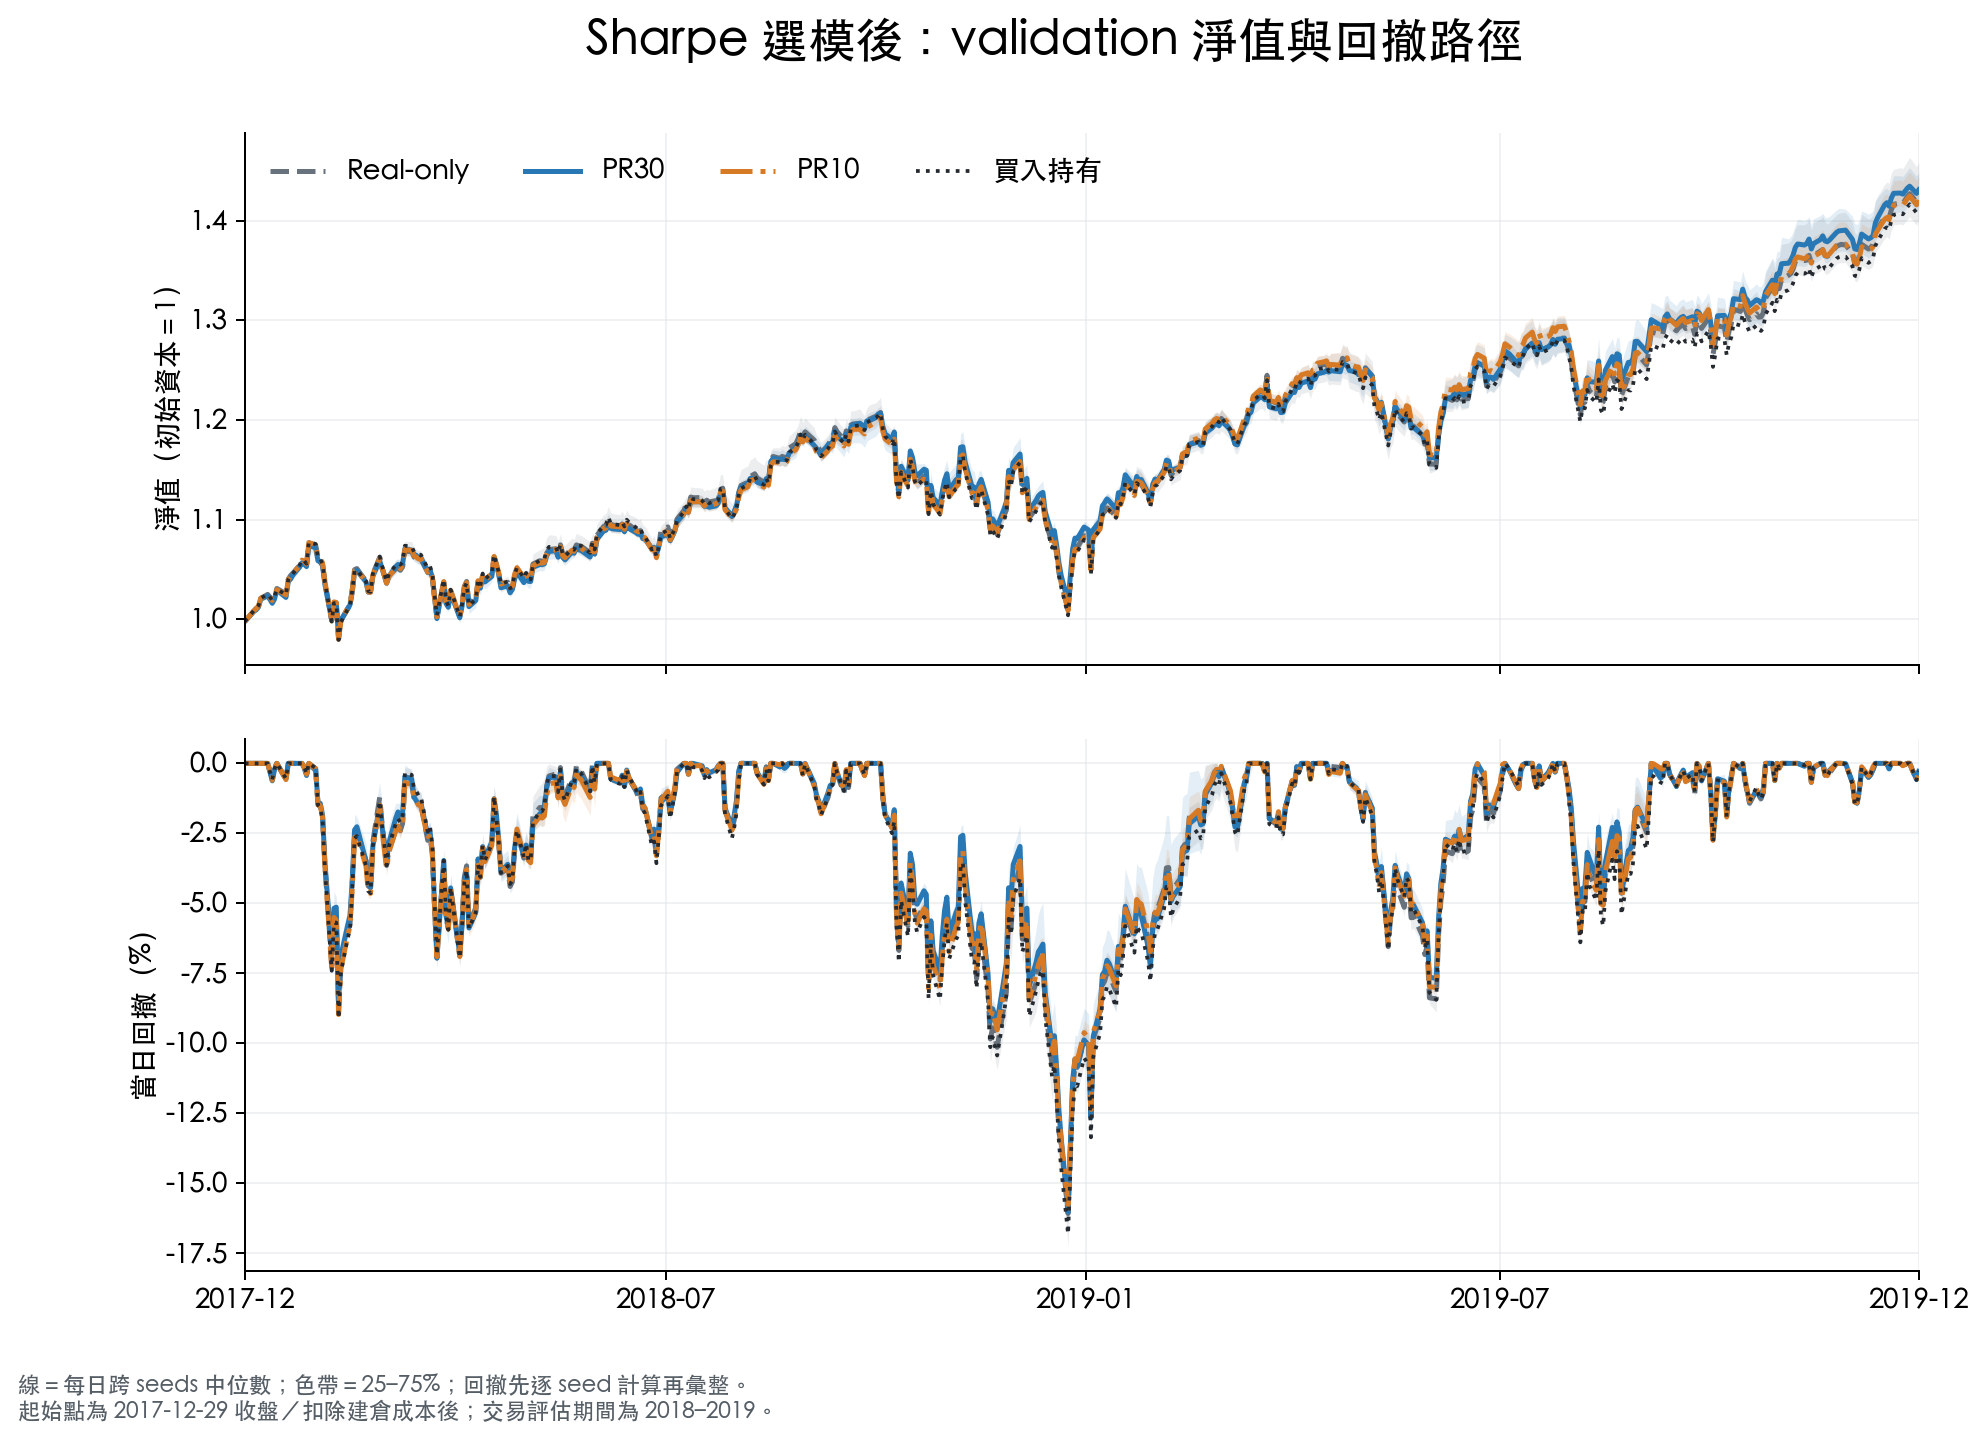

累積報酬 (%)  最大回撤 (%)
group     period                    
買入持有      2018        7.99     16.82
          2019       30.84      8.45
PR10      2018        8.67     15.81
          2019       31.80      8.08
PR30      2018        9.78     15.79
          2019       32.76      7.85
Real-only 2018        8.60     16.38
          2019       31.47      8.46

In [5]:
display(Image(filename=str(OUT / "figures/03_validation_paths.png"), width=1100))
sub = pd.read_csv(OUT / "validation_subperiods.csv", dtype={"period": str})
annual = sub[sub.period.isin(["2018", "2019"])].groupby(["group", "period"])[["return_pct", "mdd_pct"]].mean()
display(annual.rename(index=LABELS, level="group").rename(columns={"return_pct": "累積報酬 (%)", "mdd_pct": "最大回撤 (%)"}).round(2))


## 曝險與尾部損失

ES95 是該 validation 最差 5% 日報酬的平均損失幅度。單股集中度採「每日最大單股權重的全期平均」。
僅增加尾部訓練情境，不代表策略必然學會在下跌當下減碼。


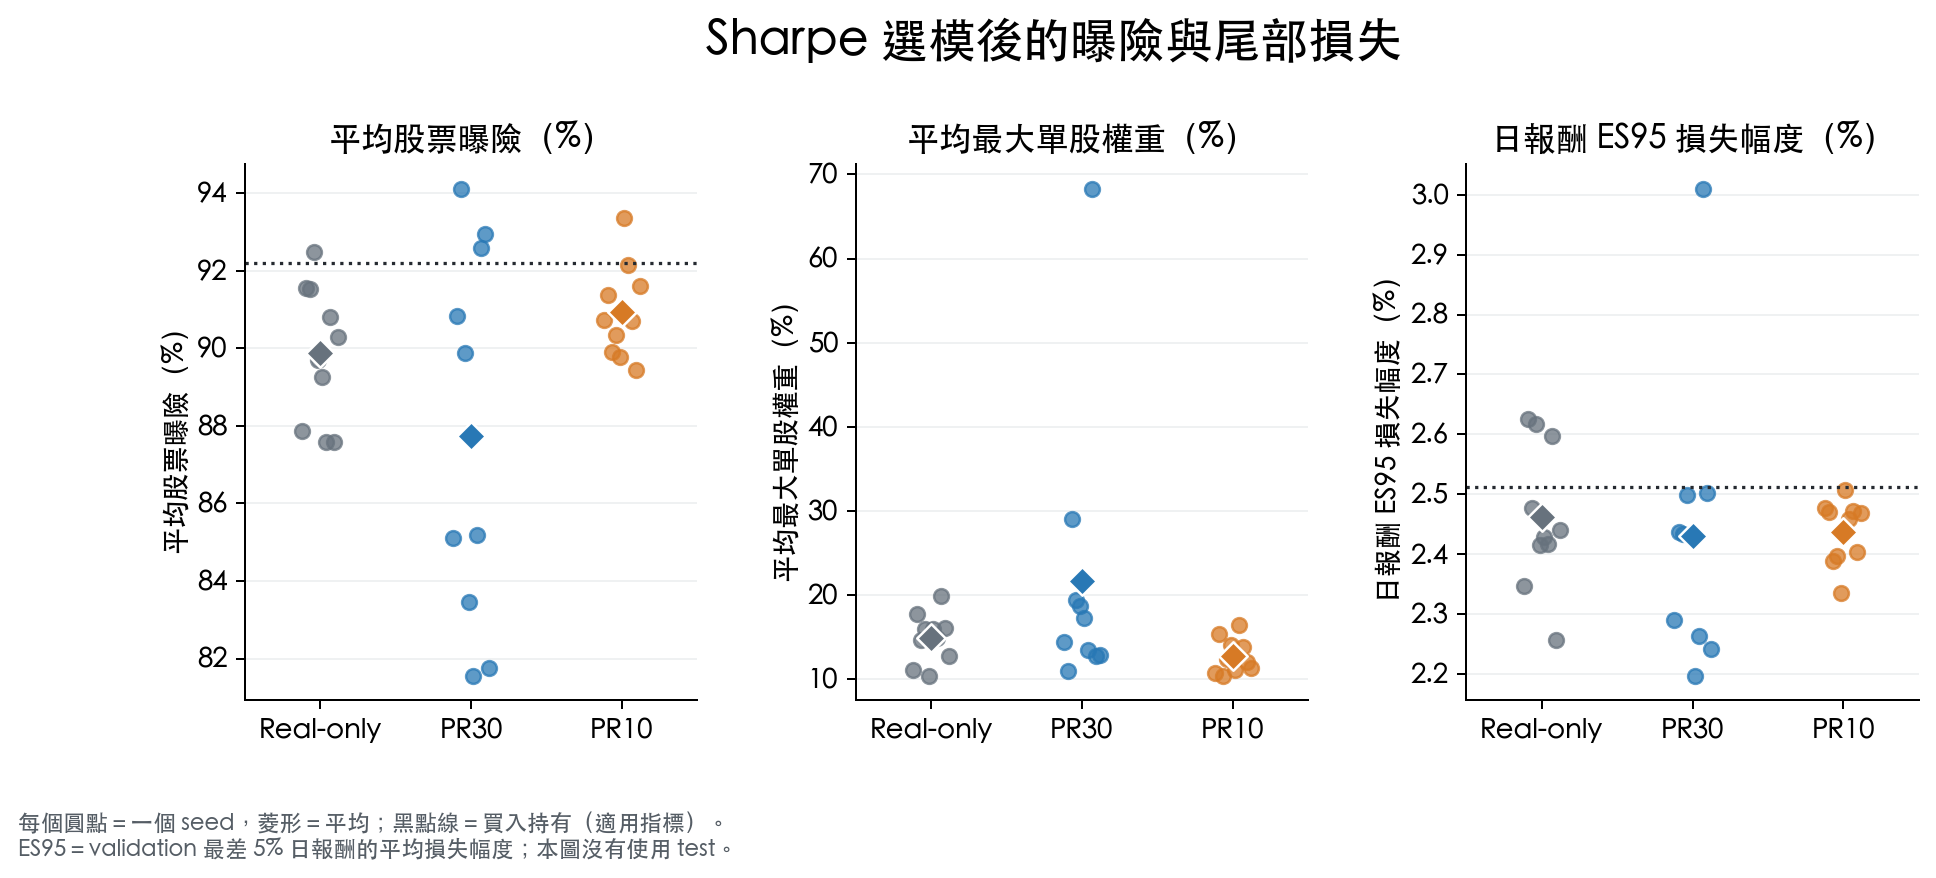

,平均股票曝險 (%),平均最大單股權重 (%),年化換手倍數,累積費用乘數損耗 (%)
group,,,,
Real-only,89.864,14.948,2.628,2.557
PR30,87.736,21.723,3.391,3.051
PR10,90.937,12.768,2.231,2.222


,episodes,synthetic_episodes,tail_pool_episodes,合成 episodes (%),尾部來源占全部 (%)
group,,,,,
PR10,169082,84719,25169,50.11,14.89
PR30,169082,84719,25807,50.11,15.26
Real-only,169152,0,0,0.00,0.00


In [6]:
display(Image(filename=str(OUT / "figures/05_exposure_and_tail.png"), width=1100))
exposure = summary[["stock_weight_pct_mean", "mean_largest_stock_weight_pct_mean", "annual_turnover_mean", "fee_factor_drag_pct_mean"]].rename(index=LABELS)
exposure.columns = ["平均股票曝險 (%)", "平均最大單股權重 (%)", "年化換手倍數", "累積費用乘數損耗 (%)"]
display(exposure.round(3))
sampling = pd.read_csv(OUT / "episode_sampling.csv")
sampling = sampling.groupby("group")[["episodes", "synthetic_episodes", "tail_pool_episodes"]].sum()
sampling["合成 episodes (%)"] = sampling.synthetic_episodes / sampling.episodes * 100
sampling["尾部來源占全部 (%)"] = sampling.tail_pool_episodes / sampling.episodes * 100
display(sampling.rename(index=LABELS).round(2))


## Seed 8 的後段行為診斷

這個指定 seed 曾出現期末報酬與 Sharpe 的明顯跳變。比較 Sharpe 選中的模型與最後 500k 模型，檢查是否伴隨集中持股。
這是個案診斷，不代表所有 seeds 都有相同行為，也不能單獨證明由取樣方式造成。


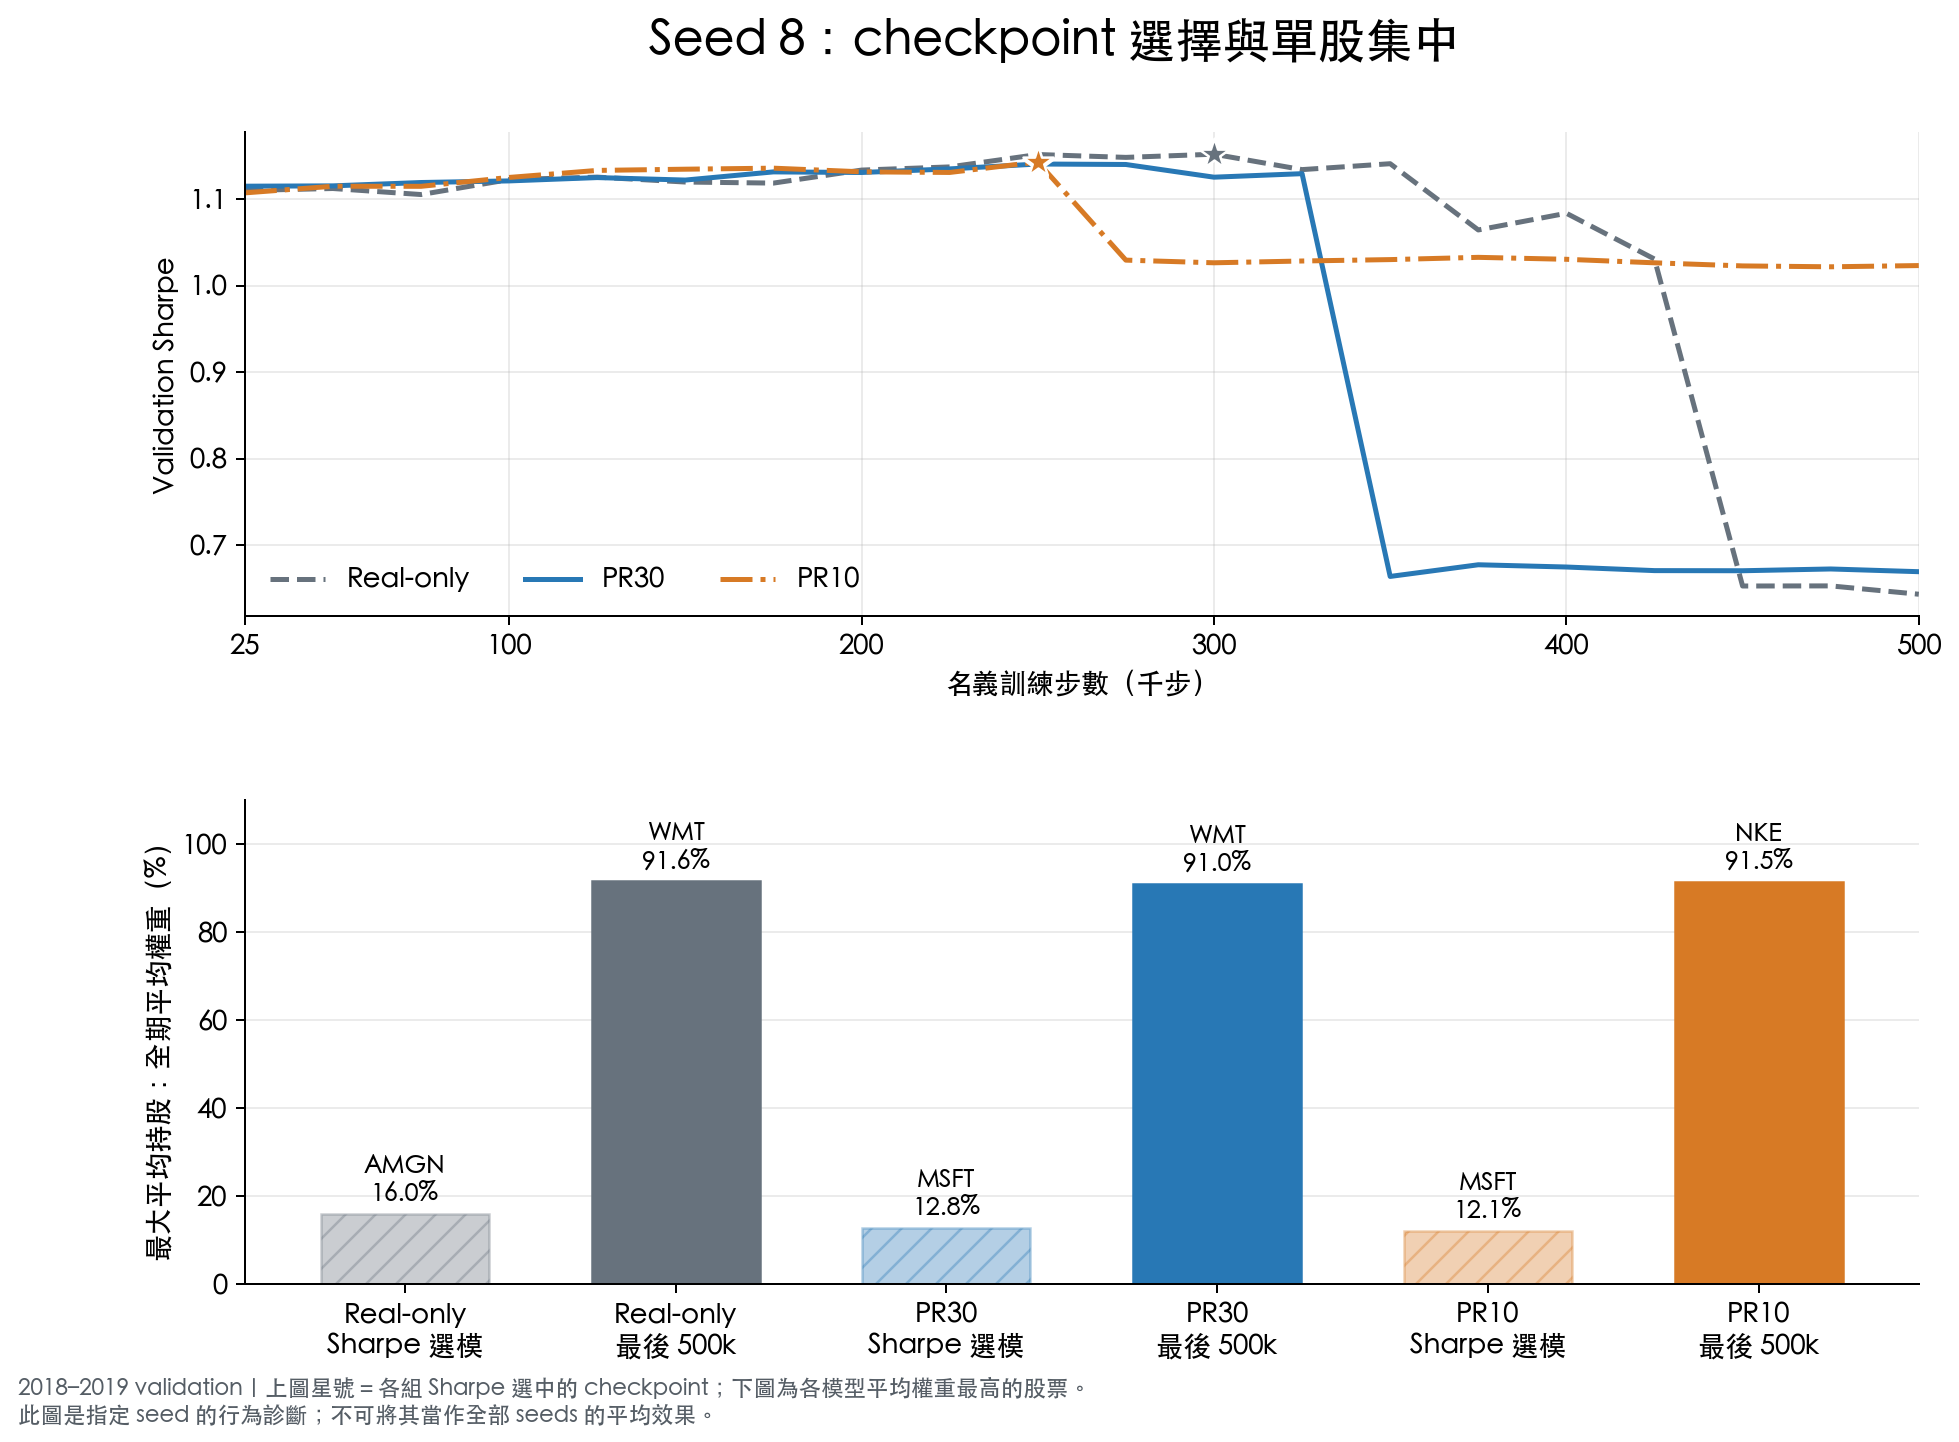

,group,stage,nominal_timesteps,largest_mean_asset,largest_asset_mean_weight_pct,return_pct,sharpe,mdd_pct
0,REAL_ONLY,selected_sharpe,300000,AMGN,16.043,39.019,1.152,14.234
1,REAL_ONLY,final,500000,WMT,91.612,26.974,0.643,22.029
2,PR30_B50,selected_sharpe,250000,MSFT,12.801,43.756,1.141,16.304
3,PR30_B50,final,500000,WMT,91.023,28.392,0.670,21.542
4,PR10_B50,selected_sharpe,250000,MSFT,12.087,41.762,1.143,15.443
5,PR10_B50,final,500000,NKE,91.500,63.296,1.023,19.898


In [7]:
display(Image(filename=str(OUT / "figures/06_seed8_checkpoint_diagnostic.png"), width=1100))
diagnostic = pd.read_csv(OUT / "diagnostics/seed8_selected_vs_final.csv")
display(diagnostic[["group", "stage", "nominal_timesteps", "largest_mean_asset", "largest_asset_mean_weight_pct", "return_pct", "sharpe", "mdd_pct"]].round(3))


## 解讀範圍與重現

- 主分析採用同一 validation 進行選模與評分；不是獨立 test。TimeDiff 的選模也使用過 2018–2019。
- 目前只涵蓋一個市場 validation 時段、一組固定生成資料，以及每組十個 PPO seeds。
- 日回撤與曝險已用選中模型重新跑 validation，並與原 valid.csv 核對；沒有重訓混合組。
- 原始 PR30／PR10 結果與新 real-only 批次各自保存，選模透過清單引用 checkpoint，不覆蓋模型。
- `analysis.json` 保存定義與限制，`source_manifest.json` 保存來源雜湊，`selected_checkpoints.csv` 保存 checkpoint 路徑與雜湊。

在 FinRL_Exp 專案根目錄重建分析（不會訓練）：

```bash
venv/bin/python -B analysis/scenario_mix/joint_sharpe_realonly_20261018/analyze.py audit
venv/bin/python -B analysis/scenario_mix/joint_sharpe_realonly_20261018/analyze.py evaluate
venv/bin/python -B analysis/scenario_mix/joint_sharpe_realonly_20261018/analyze.py summarize
venv/bin/python -B analysis/scenario_mix/joint_sharpe_realonly_20261018/diagnose_seed8.py
python -B analysis/scenario_mix/joint_sharpe_realonly_20261018/build_notebook.py
```

最後一行需使用已安裝 pandas、IPython、nbformat 與 Jinja2 的 Python；本機以 TimeDiff 的 `.venv-spx` 建置 notebook，PPO 訓練與模型重播仍使用 FinRL 的 venv。

執行驗證採單一 IPython 行程依序執行所有 cells，保留狀態與顯示輸出；不需要啟動 Jupyter kernel 或綁定本機 socket。
